# Undulator scan aggregates — photon energy × GMD

Opens the energy-mode aggregates of an undulator scan and lays them out as plain arrays.

**Data.** By default run 60559 (`Ethanol_undulator_scan_2807989445`, nominal 265–282 eV), aggregated with
`analysis/configs/aggregates_run60559_energy.py`:

```
python analysis/scripts/photon_energy.py   <combined>.h5            # per-shot VLS photon energy -> photon_energy/
python analysis/scripts/compute_aggregates.py analysis/configs/aggregates_run60559_energy.py <combined>.h5
```

**Bins.** Measured photon energy (VLS peak centre per shot, calibrated against the nominal steps) in 0.5 eV bins ×
GMD in 5 bins at the 0/20/…/100th percentiles of the binned shots (GMD ≥ 0.02 µJ). Shots without a measured energy
(VLS signal below 5σ of the dark line) are not included. Bunch slots 0–99.

**Arrays** — means over the shots of each `(energy, GMD)` cell, NaN where a cell is empty:

| name | shape | |
|---|---|---|
| `D`, `C` | `(nE, nG, n_e)`, `(nE, nG, n_i)` | electron / ion spectrum, hits per shot per bin |
| `DtD`, `CtC`, `DtC` | `(nE, nG, n_e, n_e)`, … | second moments ⟨DDᵀ⟩, ⟨CCᵀ⟩, ⟨DCᵀ⟩ |
| `G`, `GtG`, `DtG`, `CtG` | `(nE, nG)`, … | ⟨G⟩, ⟨G²⟩, ⟨DG⟩, ⟨CG⟩ for partial covariance on GMD |
| `n` | `(nE, nG)` | shots per cell |

Covariance in a cell: `DtC − D[..., :, None] * C[..., None, :]`; with `var_G = GtG − G²` and
`cov_DG = DtG − D·G`, the partial covariance on GMD subtracts `cov_DG ⊗ cov_CG / var_G`. Merging cells: weight the
means by `n` before forming covariances.

In [42]:
# ---- Parameters ---------------------------------------------------------------
# AGG_H5 = "run60559_Ethanol_undulator_scan_2807989445_aggregates_energy.h5"   # relative to config.COMBINED_DIR or absolute
AGG_H5 = "run60560_Ethanol_undulator_scan_2808016357_live_aggregates_energy.h5"

In [43]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import config
from compute_aggregates import load_aggregates

warnings.filterwarnings("ignore", message="invalid value encountered")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
TDC_PER_NS = 10

## Load

In [44]:
agg_path = Path(AGG_H5)
agg_path = agg_path if agg_path.is_absolute() else config.COMBINED_DIR / agg_path
agg = load_aggregates(agg_path)
assert agg.mode == "energy", f"expected energy-mode aggregates, got {agg.mode!r}"

# Plain arrays
D, DtD, C, CtC, DtC = agg.D, agg.DtD, agg.C, agg.CtC, agg.DtC
G, GtG, DtG, CtG = agg.G, agg.GtG, agg.DtG, agg.CtG
n = agg.n_per_bin

# Axes
E_edges, E = agg.energy_edges, agg.energy_centres                 # eV
gmd_edges = agg.gmd_edges                                         # µJ (G holds the mean GMD of each cell)
tof_e_edges = agg.tof_edges / TDC_PER_NS                          # ns
tof_i_edges = agg.ion_tof_edges / TDC_PER_NS
tof_e = 0.5 * (tof_e_edges[1:] + tof_e_edges[:-1])
tof_i = 0.5 * (tof_i_edges[1:] + tof_i_edges[:-1])

meta = agg.metadata
print(f"{agg_path.name}")
print(f"  from {Path(meta['input_h5']).name}, config {meta.get('config_path', '-')}")
print(f"  {len(E)} energy bins {E_edges[0]:.2f}-{E_edges[-1]:.2f} eV ({meta.get('energy_key')}), "
      f"{len(gmd_edges) - 1} GMD bins {np.round(gmd_edges, 3).tolist()} µJ")
print(f"  electrons {len(tof_e)} bins {tof_e_edges[0]:.0f}-{tof_e_edges[-1]:.0f} ns, "
      f"ions {len(tof_i)} bins {tof_i_edges[0]:.0f}-{tof_i_edges[-1]:.0f} ns, bunch slots {meta.get('bunch_range')}")
print(f"  {n.sum()} shots binned; left out: {meta.get('n_skipped_energy_nan')} without a photon energy, "
      f"{meta.get('n_skipped_gmd_oor')} outside the GMD bins, {meta.get('n_skipped_max_hits')} over the hit caps")
for k in ("D", "DtD", "C", "CtC", "DtC", "G", "DtG", "CtG"):
    print(f"  {k:4s} {getattr(agg, k).shape}")

run60560_Ethanol_undulator_scan_2808016357_live_aggregates_energy.h5
  from run60560_Ethanol_undulator_scan_2808016357_live.h5, config analysis/configs/aggregates_run60560_energy.py
  39 energy bins 263.75-283.25 eV (photon_energy/measured), 5 GMD bins [0.02, 0.07, 0.128, 0.205, 0.35, 4.846] µJ
  electrons 190 bins 50-1000 ns, ions 320 bins 200-3400 ns, bunch slots [0, 100]
  6940272 shots binned; left out: 601033 without a photon energy, 532808 outside the GMD bins, 35 over the hit caps
  D    (39, 5, 190)
  DtD  (39, 5, 190, 190)
  C    (39, 5, 320)
  CtC  (39, 5, 320, 320)
  DtC  (39, 5, 190, 320)
  G    (39, 5)
  DtG  (39, 5, 190)
  CtG  (39, 5, 320)


In [45]:
# Photon-energy calibration stored with the per-shot energies in the combined file
with h5py.File(meta["input_h5"] if Path(meta["input_h5"]).is_absolute()
               else REPO_ROOT / meta["input_h5"], "r") as f:
    pe = f["photon_energy"]
    cal_coef, cal_E, cal_px, cal_res = (pe[k][...] for k in ("cal_coef", "cal_energies", "cal_centres", "cal_residuals"))
print("E(pixel) = " + " + ".join(f"{c:.6g} px^{len(cal_coef) - 1 - i}" for i, c in enumerate(cal_coef)),
      f"| rms residual {np.sqrt(np.mean(cal_res ** 2)):.3f} eV over {len(cal_E)} nominal steps")

E(pixel) = -0.0570834 px^1 + 297.953 px^0 | rms residual 0.026 eV over 14 nominal steps


/tmp/ipykernel_2559827/1464230080.py:3: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  mesh = ax.pcolormesh(np.arange(len(gmd_edges)), E_edges, n, cmap="viridis")
/tmp/ipykernel_2559827/1464230080.py:4: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(mesh, ax=ax, label="shots")


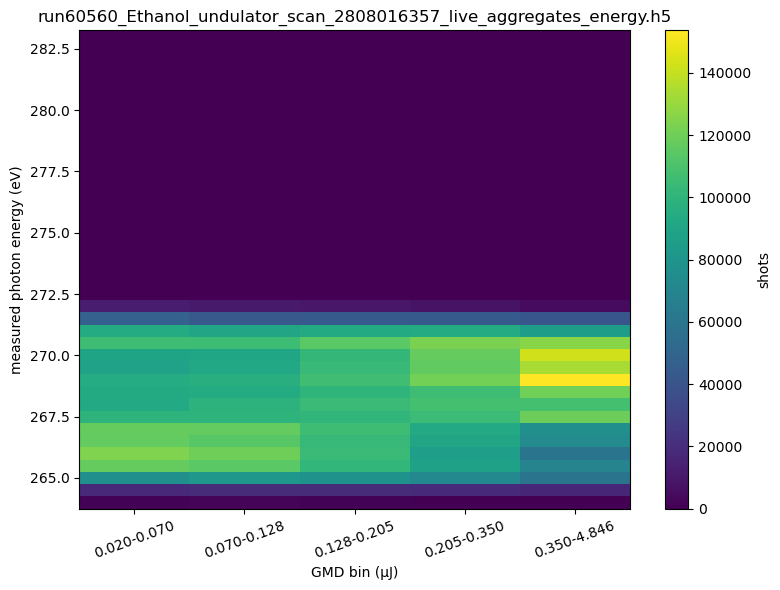

In [46]:
# Shots per cell
fig, ax = plt.subplots(figsize=(8, 6))
mesh = ax.pcolormesh(np.arange(len(gmd_edges)), E_edges, n, cmap="viridis")
fig.colorbar(mesh, ax=ax, label="shots")
ax.set_xticks(np.arange(len(gmd_edges) - 1) + 0.5,
              [f"{a:.3f}-{b:.3f}" for a, b in zip(gmd_edges[:-1], gmd_edges[1:])], rotation=20)
ax.set(xlabel="GMD bin (µJ)", ylabel="measured photon energy (eV)", title=agg_path.name)
ax.grid(False)
fig.tight_layout()
plt.show()

In [47]:
D.shape

(39, 5, 190)

(0.0, 400.0)

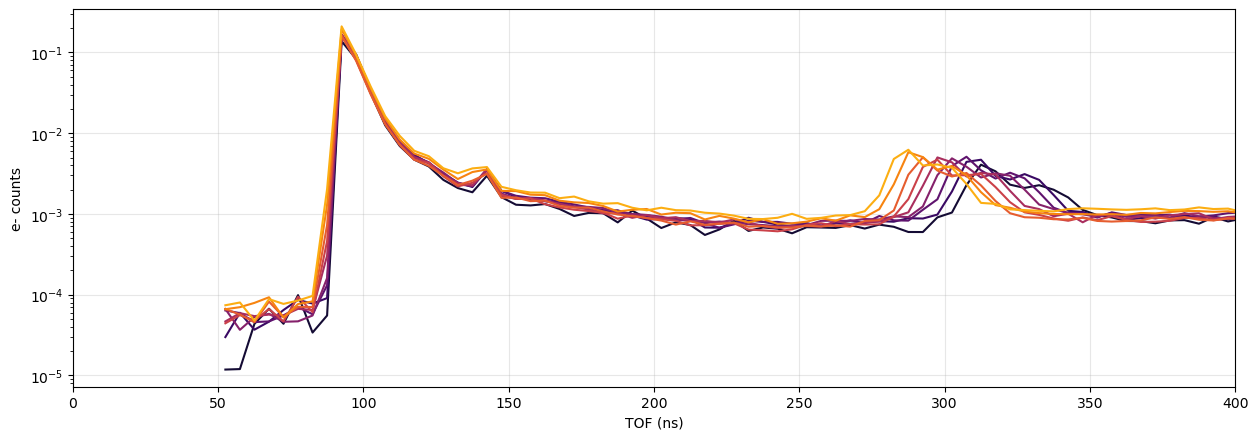

In [55]:
fig, ax = plt.subplots(figsize=(15,5))
ax.set_prop_cycle(plt.cycler('color', sns.color_palette('inferno', D[:10].shape[0])))
ax.semilogy(tof_e, D.mean(1)[1:10].T)
ax.set_xlabel('TOF (ns)')
ax.set_ylabel('e- counts')
ax.set_xlim(0, 400)

In [49]:
D.shape

(39, 5, 190)

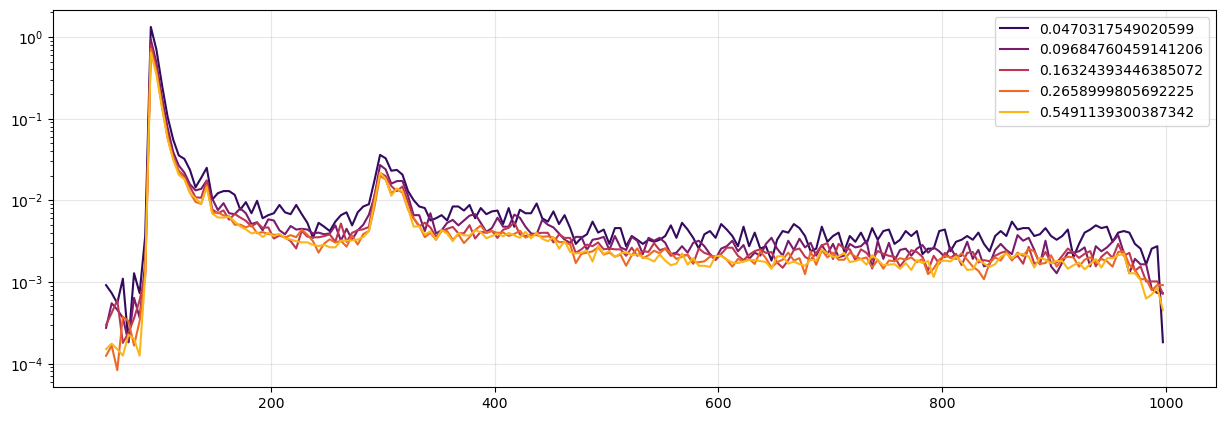

In [53]:
idx = 5
fig, ax = plt.subplots(figsize=(15,5))
ax.set_prop_cycle(plt.cycler('color', sns.color_palette('inferno', D.shape[1])))
ax.semilogy(tof_e, D[idx].T/G[idx])
# ax.plot(tof_e, D[idx].T)
ax.legend(G[idx])
# ax.set_xlim(50,200)